In [1]:
# Import libraries
import pandas as pd
import numpy as np

# Load the cleaned Swiggy dataset
file_path = r"C:\Users\ASUS\Downloads\swiggy_cleaned.csv"
df = pd.read_csv(file_path)

# Check the dataset
print("Dataset shape:", df.shape)
print("Missing ratings:", df["rating"].isna().sum())

display(df.head())

Dataset shape: (139321, 10)
Missing ratings: 33457


,restaurant_name,cuisine,rating,number_of_ratings,average_price,number_of_offers,offer_name,area,pure_veg,location
0,La Pino'Z Pizza,"Pizzas, Pastas",4.0,10.0,250,2,FLAT DEAL\nFLAT ₹125 OFF\nUSE FLAT125ABOVE ₹69...,LALA LAJPAT RAI MARKET,No,Abohar
1,The Second Wife,"Indian, North Indian",3.6,50.0,250,2,"30% OFF UPTO ₹75\nUSE TRYNEWABOVE ₹149, FLAT ₹...",Central Abohar,No,Abohar
2,Tasty Bites,"Italian, Beverages",3.8,10.0,200,1,FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500,Central Abohar,Yes,Abohar
3,Food Studio,"Pizzas, Burgers",3.5,8.0,49,5,"50% OFF UPTO ₹100\nUSE TRYNEWABOVE ₹129, FLAT ...",Central Abohar,Yes,Abohar
4,Roll Express,"Fast Food, Snacks",4.3,100.0,200,2,DEAL OF DAY\n10% OFF UPTO ₹40\nUSE STEALDEALAB...,Circular Road,No,Abohar


In [2]:
# Check data types and missing values
print("DATA TYPES")
display(df.dtypes)

print("\nMISSING VALUES")
display(df.isnull().sum().sort_values(ascending=False))

DATA TYPES


restaurant_name          str
cuisine                  str
rating               float64
number_of_ratings    float64
average_price          int64
number_of_offers       int64
offer_name               str
area                     str
pure_veg                 str
location                 str
dtype: object


MISSING VALUES


number_of_ratings    33457
rating               33457
cuisine                  0
restaurant_name          0
average_price            0
number_of_offers         0
offer_name               0
area                     0
pure_veg                 0
location                 0
dtype: int64

In [3]:
# Keep rows with known restaurant ratings
df_model = df.dropna(subset=["rating"]).copy()

# Create new offer-related features
df_model["has_offer"] = (
    df_model["number_of_offers"] > 0
).astype(int)

# Calculate average offers per restaurant record
df_model["offers_per_rating_count"] = (
    df_model["number_of_offers"] /
    df_model["number_of_ratings"].replace(0, np.nan)
)

# Check the engineered features
print("Modeling dataset shape:", df_model.shape)
print("Missing target ratings:", df_model["rating"].isna().sum())

display(
    df_model[
        ["number_of_offers", "number_of_ratings",
         "has_offer", "offers_per_rating_count", "rating"]
    ].head()
)

Modeling dataset shape: (105864, 12)
Missing target ratings: 0


,number_of_offers,number_of_ratings,has_offer,offers_per_rating_count,rating
0,2,10.0,1,0.200,4.0
1,2,50.0,1,0.040,3.6
2,1,10.0,1,0.100,3.8
3,5,8.0,1,0.625,3.5
4,2,100.0,1,0.020,4.3


In [4]:
from sklearn.model_selection import train_test_split

# Select input features, including the new engineered features
feature_columns = [
    "cuisine",
    "number_of_ratings",
    "average_price",
    "number_of_offers",
    "area",
    "pure_veg",
    "location",
    "has_offer",
    "offers_per_rating_count"
]

X = df_model[feature_columns].copy()
y = df_model["rating"].copy()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (84691, 9)
Testing features: (21173, 9)
Training targets: (84691,)
Testing targets: (21173,)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify categorical and numerical features
categorical_features = [
    "cuisine", "area", "pure_veg", "location"
]

numerical_features = [
    "number_of_ratings",
    "average_price",
    "number_of_offers",
    "has_offer",
    "offers_per_rating_count"
]

# Preprocess categorical and numerical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_features),
    ("numerical", numerical_pipeline, numerical_features)
])

print("Improved preprocessing pipeline created successfully!")

Improved preprocessing pipeline created successfully!


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Build the Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=2
    ))
])

# Use a smaller sample to keep tuning manageable
X_tune = X_train.sample(
    n=min(12000, len(X_train)),
    random_state=42
)
y_tune = y_train.loc[X_tune.index]

# Define hyperparameters to test
param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [8, 12, None],
    "model__min_samples_leaf": [5, 10]
}

# Tune using 3-fold cross-validation
tuning = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=4,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

tuning.fit(X_tune, y_tune)

print("Best parameters:", tuning.best_params_)
print("Best cross-validation MAE:", round(-tuning.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__n_estimators': 50, 'model__min_samples_leaf': 5, 'model__max_depth': 8}
Best cross-validation MAE: 0.3493


In [7]:
# Get the best model configuration from tuning
best_rf_model = tuning.best_estimator_

# Train it on the full training dataset
best_rf_model.fit(X_train, y_train)

print("Tuned Random Forest trained on full training data!")

Tuned Random Forest trained on full training data!


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict ratings on the test dataset
y_pred_tuned = best_rf_model.predict(X_test)

# Calculate evaluation metrics
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_tuned = r2_score(y_test, y_pred_tuned)

print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")
print("MAE:", round(mae_tuned, 4))
print("RMSE:", round(rmse_tuned, 4))
print("R2 Score:", round(r2_tuned, 4))

TUNED RANDOM FOREST RESULTS
---------------------------
MAE: 0.3467
RMSE: 0.4762
R2 Score: 0.0759


In [9]:
# Compare previous models with the tuned model
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression (Task 2)",
        "Random Forest (Task 2)",
        "Tuned Random Forest (Task 3)"
    ],
    "MAE": [
        0.3447,
        0.3463,
        mae_tuned
    ],
    "RMSE": [
        0.4725,
        0.4757,
        rmse_tuned
    ],
    "R2 Score": [
        0.0903,
        0.0776,
        r2_tuned
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression (Task 2),0.3447,0.4725,0.0903
1,Random Forest (Task 2),0.3463,0.4757,0.0776
2,Tuned Random Forest (Task 3),0.3467,0.4762,0.0759


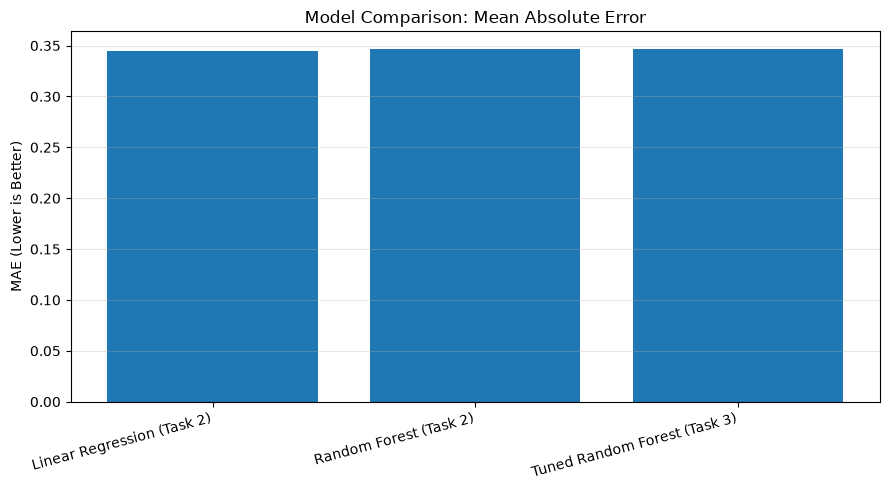

In [10]:
import matplotlib.pyplot as plt

# Compare MAE across all three models
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.title("Model Comparison: Mean Absolute Error")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3: Model Improvement and Optimization — Findings

### Techniques Applied
- **Feature Engineering:** Created `has_offer` to indicate whether an offer is available and `offers_per_rating_count` as an additional feature.
- **Hyperparameter Tuning:** Used `RandomizedSearchCV` to test Random Forest configurations.
- **Cross-Validation:** Applied 3-fold cross-validation to compare parameter combinations using MAE.
- **Preprocessing Pipeline:** Used median imputation for numerical features and most-frequent imputation plus One-Hot Encoding for categorical features.

### Model Comparison

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression (Task 2) | 0.3447 | 0.4725 | 0.0903 |
| Random Forest (Task 2) | 0.3463 | 0.4757 | 0.0776 |
| Tuned Random Forest (Task 3) | 0.3467 | 0.4762 | 0.0759 |

### Findings
The tuned Random Forest achieved a cross-validation MAE of 0.3493. On the test dataset, its MAE was 0.3467, RMSE was 0.4762, and R² score was 0.0759.

The tuned model did not outperform the previous models. Linear Regression had the lowest MAE and RMSE and the highest R² score among the three reported results. This suggests that the additional features and selected Random Forest parameters did not provide a measurable improvement in this experiment.

### Limitations
The earlier Random Forest model was trained on a smaller sample, while the tuned model was trained on the full training set. Therefore, their results are not a perfectly controlled comparison. The hyperparameter search was also performed on a 12,000-row sample to reduce computation time.

### Conclusion
This task demonstrated feature engineering, hyperparameter tuning, cross-validation, and model evaluation. The experiment showed that tuning does not always improve model performance. Future work could include a controlled comparison using identical training samples, additional feature engineering, and testing alternative regression models.
